# Strava Munro Bagging — Exploration

`data/strava_raw/qualifying_activities.jsonl` holds every Strava activity whose
summitbag.com-generated description tags at least one hill summit. Most of
those are Munros, but plenty are Corbetts, Grahams, English/Welsh Wainwrights,
or hills abroad. `scripts/extract_munro_activities.py` cross-references every
tagged summit against the DoBIH database (`data/hills.yaml`) and keeps only
the activities that bagged at least one **Munro** (a Scottish hill ≥ 914 m /
3000 ft, per the SMC list — 282 of them).

This notebook explores what's left: bagging progress, geography, seasonality,
and route/elevation detail for the biggest days out.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
import yaml

DATA = Path("..") / "data"
STRAVA = DATA / "strava_raw"

pd.set_option("display.max_columns", 20)

## 1. Palette & chart chrome

A small fixed palette used consistently across every chart below, rather than matplotlib's default cycle.

In [2]:
# Categorical hues (fixed order - never reassigned/cycled between charts)
CAT = {
    "blue":    "#2a78d6",
    "orange":  "#eb6834",
    "aqua":    "#1baf7a",
    "yellow":  "#eda100",
    "magenta": "#e87ba4",
    "green":   "#008300",
    "violet":  "#4a3aa7",
    "red":     "#e34948",
}
# Sequential blue ramp, light -> dark
SEQ_BLUE = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
MUTED_GRAY = "#c3c2b7"   # "not yet done" / de-emphasis
INK = "#0b0b0b"
INK_SECONDARY = "#52514e"
INK_MUTED = "#898781"
GRID = "#e1e0d9"
AXIS = "#c3c2b7"
SURFACE = "#fcfcfb"

plt.rcParams.update({
    "figure.dpi": 120,
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": AXIS,
    "axes.labelcolor": INK_SECONDARY,
    "axes.titlecolor": INK,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "grid.linestyle": "-",
    "xtick.color": INK_MUTED,
    "ytick.color": INK_MUTED,
    "text.color": INK,
    "font.size": 11,
    "font.family": "sans-serif",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "lines.linewidth": 2,
    "legend.frameon": False,
})

## 2. Load data

- `data/hills.yaml` — the full DoBIH database, filtered to the 282 official Munros.
- `data/DoBIH_v17_3.csv` — same database with lat/lon and SMC region groupings (not carried through the yaml conversion).
- `data/strava_raw/munro_activities.jsonl` / `munro_summits.csv` — output of `scripts/extract_munro_activities.py`.

In [3]:
with open(DATA / "hills.yaml") as f:
    hills_raw = yaml.safe_load(f)

dobih = pd.read_csv(DATA / "DoBIH_v17_3.csv", low_memory=False, index_col="Number")

all_munros = dobih[dobih["M"] == 1][["Name", "Metres", "Latitude", "Longitude", "Region"]].copy()
all_munros["Region"] = all_munros["Region"].str.split(": ", n=1).str[1]
print(f"{len(all_munros)} official Munros in the DoBIH database")
all_munros.head()

282 official Munros in the DoBIH database


,Name,Metres,Latitude,Longitude,Region
Number,,,,,
1,Ben Chonzie,931.0,56.453851,-3.992057,Loch Tay to Perth
17,Ben Vorlich,985.3,56.342680,-4.219448,Strathyre to Strathallan
18,Stuc a' Chroin,973.0,56.329315,-4.237533,Strathyre to Strathallan
26,Ben More,1174.0,56.385952,-4.540087,Loch Lomond to Strathyre
27,Stob Binnein,1165.0,56.370717,-4.535753,Loch Lomond to Strathyre


In [4]:
activities = []
with open(STRAVA / "munro_activities.jsonl") as f:
    for line in f:
        activities.append(json.loads(line))

acts = pd.DataFrame(activities)
acts["date"] = pd.to_datetime(acts["date"])
acts = acts.sort_values("date").reset_index(drop=True)

summits = pd.read_csv(STRAVA / "munro_summits.csv")
summits["date"] = pd.to_datetime(summits["date"])
summits = summits.sort_values("date")
munro_summits = summits[summits["is_munro"]].copy()

print(f"{len(acts)} activities bagged at least one Munro")
print(f"{len(munro_summits)} Munro summit-tags across those activities")
print(f"{munro_summits['dobih_number'].nunique()} / {len(all_munros)} unique Munros bagged "
      f"({munro_summits['dobih_number'].nunique() / len(all_munros):.1%})")

117 activities bagged at least one Munro
287 Munro summit-tags across those activities
272 / 282 unique Munros bagged (96.5%)


## 3. Compleation progress

Cumulative count of *distinct* Munros bagged over time, against the 282 target.

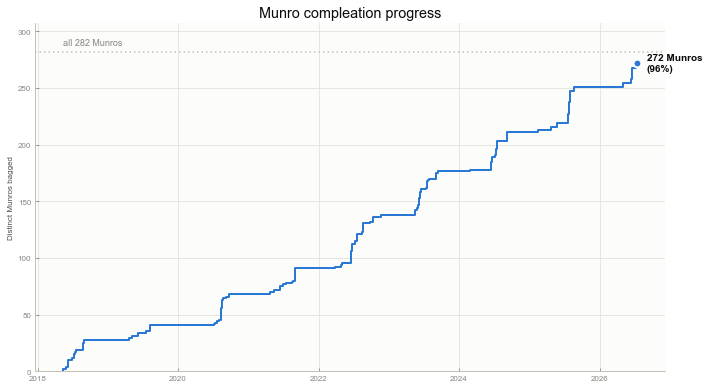

In [5]:
first_bagged = munro_summits.groupby("dobih_number")["date"].min().sort_values()
cum_unique = pd.Series(range(1, len(first_bagged) + 1), index=first_bagged.values)

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.step(cum_unique.index, cum_unique.values, where="post", color=CAT["blue"], linewidth=2)
ax.axhline(len(all_munros), color=MUTED_GRAY, linewidth=1.5, linestyle=(0, (1, 2)))
ax.text(cum_unique.index.min(), len(all_munros) + 4, f"all {len(all_munros)} Munros",
        color=INK_MUTED, fontsize=9, va="bottom")

last_x, last_y = cum_unique.index[-1], cum_unique.values[-1]
ax.scatter([last_x], [last_y], s=60, color=CAT["blue"], zorder=5,
           edgecolor=SURFACE, linewidth=2)
ax.annotate(f"{last_y} Munros\n({last_y/len(all_munros):.0%})", xy=(last_x, last_y),
            xytext=(10, 0), textcoords="offset points", va="center",
            color=INK, fontsize=10, fontweight="bold")

ax.set_ylim(0, len(all_munros) + 25)
ax.set_ylabel("Distinct Munros bagged")
ax.set_title("Munro compleation progress")
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.tight_layout()
plt.show()

In [6]:
# Simple pace-based projection: Munros/year over the last full 3 years of activity
recent_years = munro_summits[munro_summits["date"] >= munro_summits["date"].max() - pd.DateOffset(years=3)]
new_per_year = (recent_years.drop_duplicates("dobih_number")
                .groupby(recent_years["date"].dt.year)["dobih_number"].nunique())
pace = new_per_year.mean()
remaining = len(all_munros) - cum_unique.iloc[-1]

if pace > 0:
    years_left = remaining / pace
    print(f"Recent pace: ~{pace:.0f} new Munros/year -> naive projection of "
          f"~{years_left:.1f} more years to compleation "
          f"(around {munro_summits['date'].max().year + years_left:.0f}, "
          "ignoring that the easiest/nearest hills tend to go first).")

Recent pace: ~29 new Munros/year -> naive projection of ~0.3 more years to compleation (around 2026, ignoring that the easiest/nearest hills tend to go first).


## 4. Map: bagged vs. still to do

A rough equirectangular projection (longitude scaled by cos(mean latitude)) — good enough at Scotland's scale, no mapping library required.

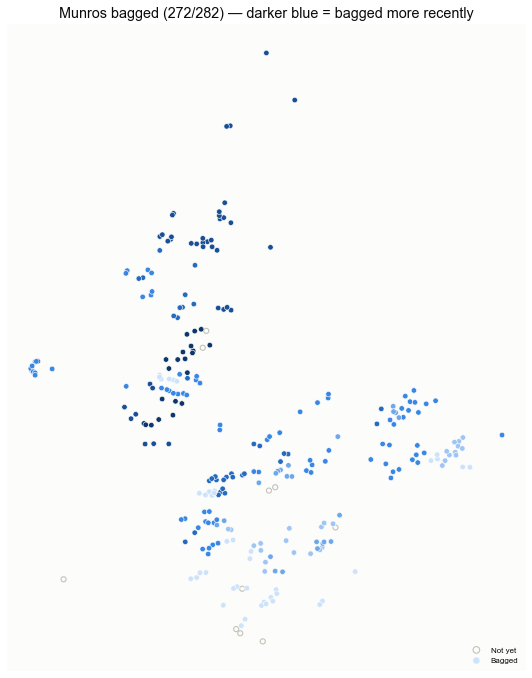

In [7]:
bagged_lookup = first_bagged.to_dict()
munro_map = all_munros.copy()
munro_map["first_bagged"] = munro_map.index.map(bagged_lookup)
munro_map["bagged"] = munro_map["first_bagged"].notna()

mean_lat = np.radians(munro_map["Latitude"].mean())
x = munro_map["Longitude"] * np.cos(mean_lat)
y = munro_map["Latitude"]

fig, ax = plt.subplots(figsize=(7.5, 10))

todo = ~munro_map["bagged"]
ax.scatter(x[todo], y[todo], s=26, facecolor="none", edgecolor=MUTED_GRAY, linewidth=1.1, label="Not yet")

done = munro_map["bagged"]
years_since = munro_map.loc[done, "first_bagged"].dt.year
year_norm = (years_since - years_since.min()) / max(1, (years_since.max() - years_since.min()))
colors = [SEQ_BLUE[int(v * (len(SEQ_BLUE) - 1))] for v in year_norm]
ax.scatter(x[done], y[done], s=30, color=colors, edgecolor=SURFACE, linewidth=0.6,
           label="Bagged", zorder=3)

ax.set_aspect("equal")
ax.set_xticks([])
ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_visible(False)
ax.grid(False)
ax.set_title(f"Munros bagged ({done.sum()}/{len(munro_map)}) — darker blue = bagged more recently")
ax.legend(loc="lower right", markerscale=1.3)
fig.tight_layout()
plt.show()

## 5. Regional completion

SMC regional groupings — where's finished, where's left.

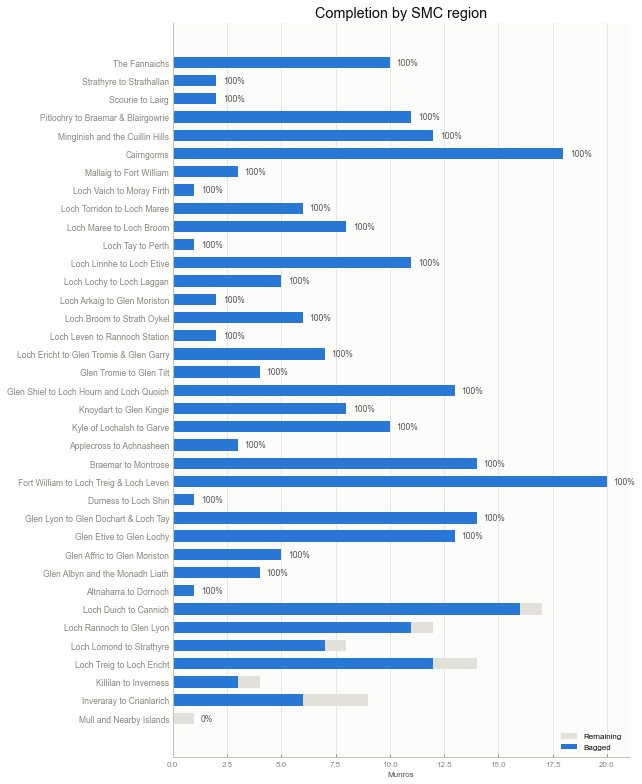

In [8]:
region_stats = (munro_map.groupby("Region")
                .agg(total=("bagged", "size"), bagged=("bagged", "sum"))
                .assign(pct=lambda d: d["bagged"] / d["total"])
                .sort_values("pct"))

fig, ax = plt.subplots(figsize=(9, 11))
yy = np.arange(len(region_stats))
ax.barh(yy, region_stats["total"], color=GRID, height=0.62, label="Remaining")
ax.barh(yy, region_stats["bagged"], color=CAT["blue"], height=0.62, label="Bagged")

for i, (pct, total) in enumerate(zip(region_stats["pct"], region_stats["total"])):
    if pct in (0, 1):
        ax.text(total + 0.3, i, f"{pct:.0%}", va="center", fontsize=8.5, color=INK_SECONDARY)

ax.set_yticks(yy)
ax.set_yticklabels(region_stats.index, fontsize=8.5)
ax.set_xlabel("Munros")
ax.set_title("Completion by SMC region")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

## 6. Activity patterns

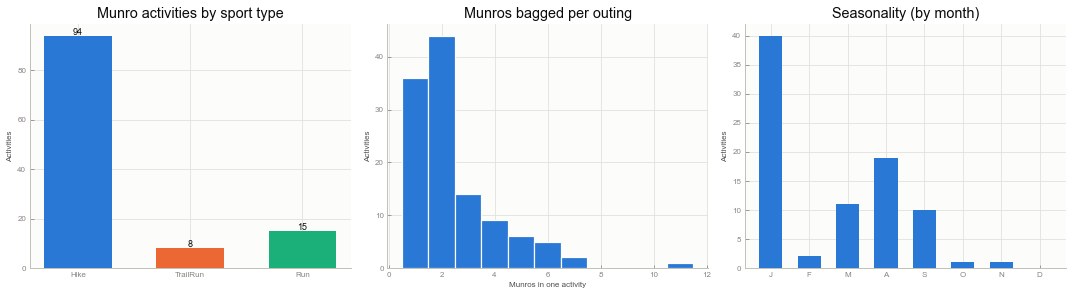

In [9]:
sport_counts = acts["sport_type"].value_counts()
sport_order = ["Hike", "TrailRun", "Run", "Ride"]
sport_counts = sport_counts.reindex([s for s in sport_order if s in sport_counts.index]).fillna(0)
colors = [CAT["blue"], CAT["orange"], CAT["aqua"], CAT["yellow"]][:len(sport_counts)]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

ax = axes[0]
bars = ax.bar(sport_counts.index, sport_counts.values, color=colors, width=0.6)
for b, v in zip(bars, sport_counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.5, int(v), ha="center", fontsize=9, color=INK)
ax.set_title("Munro activities by sport type")
ax.set_ylabel("Activities")

ax = axes[1]
ax.hist(acts["munro_count"], bins=np.arange(0.5, acts["munro_count"].max() + 1.5, 1),
        color=CAT["blue"], edgecolor=SURFACE, linewidth=1.2)
ax.set_title("Munros bagged per outing")
ax.set_xlabel("Munros in one activity")
ax.set_ylabel("Activities")

ax = axes[2]
month_counts = acts["date"].dt.month.value_counts().reindex(range(1, 13), fill_value=0)
month_labels = ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"]
ax.bar(month_labels, month_counts.values, color=CAT["blue"], width=0.6)
ax.set_title("Seasonality (by month)")
ax.set_ylabel("Activities")

fig.tight_layout()
plt.show()

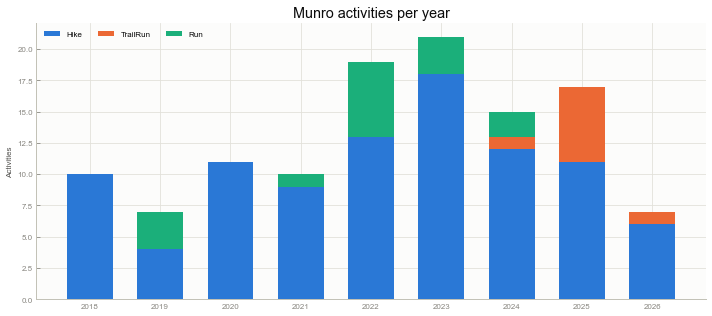

In [10]:
acts["year"] = acts["date"].dt.year
by_year_sport = acts.pivot_table(index="year", columns="sport_type", values="id",
                                  aggfunc="count", fill_value=0)
by_year_sport = by_year_sport[[c for c in sport_order if c in by_year_sport.columns]]

fig, ax = plt.subplots(figsize=(10, 4.5))
bottom = np.zeros(len(by_year_sport))
for sport, color in zip(by_year_sport.columns, colors):
    ax.bar(by_year_sport.index, by_year_sport[sport], bottom=bottom, color=color,
           label=sport, width=0.65)
    bottom += by_year_sport[sport].values

ax.set_title("Munro activities per year")
ax.set_ylabel("Activities")
ax.set_xticks(by_year_sport.index)
ax.legend(loc="upper left", ncol=len(by_year_sport.columns))
fig.tight_layout()
plt.show()

## 7. Effort: distance, elevation, and Munro count

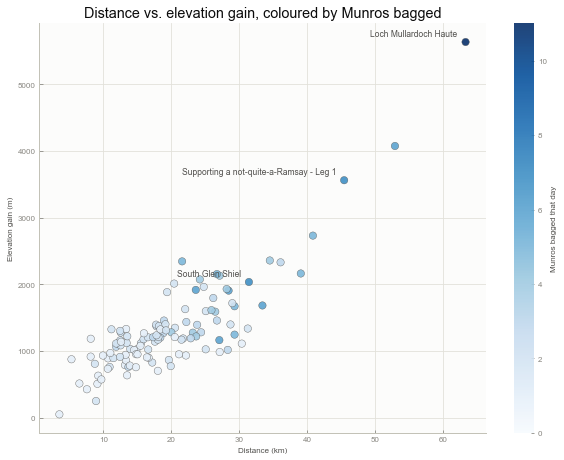

In [11]:
fig, ax = plt.subplots(figsize=(8.5, 6.5))
sc = ax.scatter(acts["distance_m"] / 1000, acts["elevation_gain_m"],
                 c=acts["munro_count"], cmap="Blues", vmin=0, s=55,
                 edgecolor=INK_SECONDARY, linewidth=0.4, alpha=0.9)
cbar = fig.colorbar(sc, ax=ax)
cbar.set_label("Munros bagged that day")
cbar.outline.set_visible(False)

top = acts.nlargest(3, "munro_count")
x_mid = (acts["distance_m"] / 1000).median()
for _, row in top.iterrows():
    x_val = row["distance_m"] / 1000
    on_right = x_val > x_mid
    ax.annotate(row["name"], xy=(x_val, row["elevation_gain_m"]),
                xytext=(-8 if on_right else 8, 6), textcoords="offset points",
                ha="right" if on_right else "left", fontsize=8.5, color=INK_SECONDARY)

ax.set_xlabel("Distance (km)")
ax.set_ylabel("Elevation gain (m)")
ax.set_title("Distance vs. elevation gain, coloured by Munros bagged")
fig.tight_layout()
plt.show()

## 8. Height distribution: bagged vs. still to do

Are the biggest, remotest Munros being saved for last, or knocked off early?

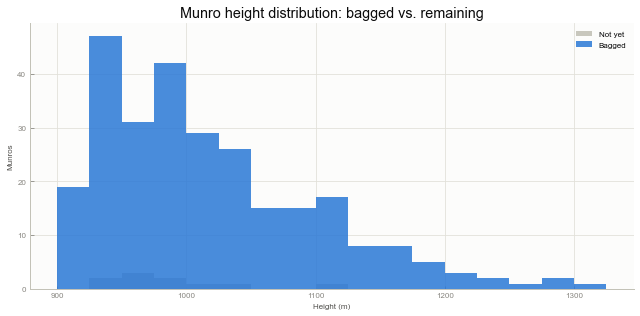

Median height - bagged:   999.25 m
Median height - not yet:  977.35 m


In [12]:
bins = np.arange(900, 1350, 25)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(munro_map.loc[~munro_map["bagged"], "Metres"], bins=bins, color=MUTED_GRAY,
        label="Not yet", alpha=0.9)
ax.hist(munro_map.loc[munro_map["bagged"], "Metres"], bins=bins, color=CAT["blue"],
        label="Bagged", alpha=0.85)
ax.set_xlabel("Height (m)")
ax.set_ylabel("Munros")
ax.set_title("Munro height distribution: bagged vs. remaining")
ax.legend()
fig.tight_layout()
plt.show()

print("Median height - bagged:  ", munro_map.loc[munro_map["bagged"], "Metres"].median(), "m")
print("Median height - not yet: ", munro_map.loc[~munro_map["bagged"], "Metres"].median(), "m")

## 9. Biggest days out

In [13]:
top_days = acts.nlargest(10, "munro_count")[
    ["date", "name", "sport_type", "munro_count", "distance_m", "elevation_gain_m"]
].copy()
top_days["date"] = top_days["date"].dt.date
top_days["distance_km"] = (top_days["distance_m"] / 1000).round(1)
top_days = top_days.drop(columns="distance_m").rename(columns={
    "name": "activity", "munro_count": "munros", "elevation_gain_m": "ascent_m"
})
top_days[["date", "activity", "sport_type", "munros", "distance_km", "ascent_m"]]

,date,activity,sport_type,munros,distance_km,ascent_m
113,2026-06-20,Loch Mullardoch Haute,Hike,11,63.3,5634.0
52,2022-08-20,South Glen Shiel,Hike,7,31.4,2034.1
109,2025-09-27,Supporting a not-quite-a-Ramsay - Leg 1,TrailRun,7,45.4,3561.0
2,2018-06-06,The Brothers and Sisters of Kintail,Hike,6,23.6,1915.9
8,2018-08-22,Western Mamores,Hike,6,33.4,1682.3
21,2020-08-11,Flavour of the Mounth,Hike,6,27.1,1162.5
37,2021-09-02,Barbequed in Ben Alder Forest,Hike,6,28.4,1904.8
90,2024-07-15,Monar Forest,Hike,6,52.9,4074.4
22,2020-08-13,A day of the Mounth,Hike,5,29.3,1244.8
42,2022-06-16,Ey Five,Hike,5,29.3,1670.1


## 10. Route & elevation detail for the biggest days

Uses whatever's in `data/strava_raw/streams/` — run `scripts/extract_munro_activities.py`
first, and fetch any missing streams via the Strava MCP `get_activity_streams`
tool (saved as `data/strava_raw/streams/{activity_id}.json`) to fill this section in fully.

120 activities have usable local GPS streams (0 file(s) skipped as empty/malformed)
116 overlap with the Munro activity set


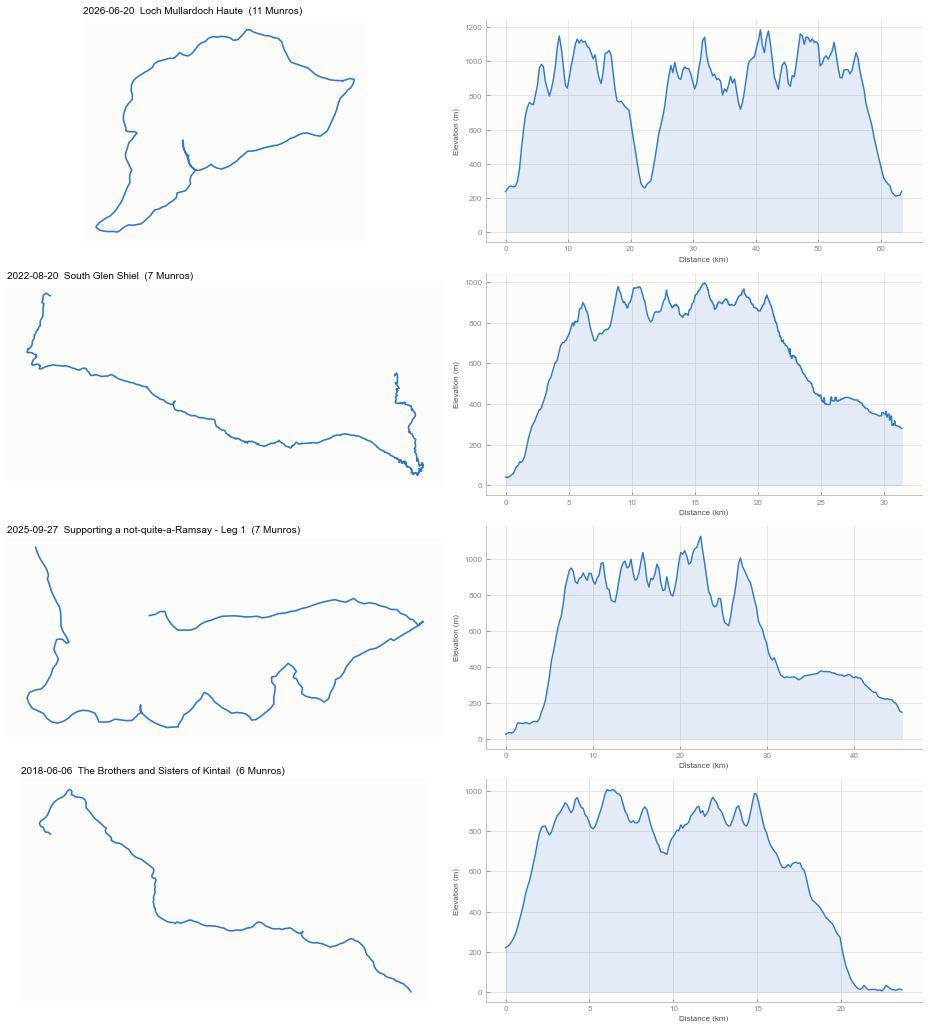

In [14]:
streams_dir = STRAVA / "streams"

def load_stream(path):
    """Tolerate stray trailing bytes / placeholder files from earlier fetch attempts."""
    with open(path) as f:
        text = f.read()
    try:
        obj, end = json.JSONDecoder().raw_decode(text)
    except (json.JSONDecodeError, ValueError):
        return None
    if not isinstance(obj, dict) or not obj:
        return None
    return obj

available = {}
for p in streams_dir.glob("*.json"):
    obj = load_stream(p)
    if obj is not None:
        available[p.stem] = obj
skipped = len(list(streams_dir.glob("*.json"))) - len(available)
print(f"{len(available)} activities have usable local GPS streams "
      f"({skipped} file(s) skipped as empty/malformed)")
print(f"{len(set(available) & set(acts['id']))} overlap with the Munro activity set")

candidates = acts[acts["id"].isin(available)].nlargest(4, "munro_count")

if candidates.empty:
    print("No overlap yet between fetched streams and Munro activities - nothing to plot.")
else:
    fig, axes = plt.subplots(len(candidates), 2, figsize=(13, 3.6 * len(candidates)))
    if len(candidates) == 1:
        axes = axes.reshape(1, 2)

    for row_i, (_, row) in enumerate(candidates.iterrows()):
        s = available[row["id"]]

        ax_map, ax_ele = axes[row_i]

        if "location" in s and s["location"]:
            loc = np.array(s["location"])
            lat, lon = loc[:, 0], loc[:, 1]
            mlat = np.radians(lat.mean())
            ax_map.plot(lon * np.cos(mlat), lat, color=CAT["blue"], linewidth=1.6)
            ax_map.set_aspect("equal")
            ax_map.set_xticks([])
            ax_map.set_yticks([])
            for spine in ax_map.spines.values():
                spine.set_visible(False)
            ax_map.grid(False)
        else:
            ax_map.axis("off")
            ax_map.text(0.5, 0.5, "no location stream", ha="center", va="center", color=INK_MUTED)

        if "altitude" in s and s["altitude"]:
            alt = np.array(s["altitude"])
            if "distance" in s and s["distance"]:
                dist = np.array(s["distance"]) / 1000
            else:
                dist = np.arange(len(alt))
            ax_ele.fill_between(dist, alt, color=CAT["blue"], alpha=0.12)
            ax_ele.plot(dist, alt, color=CAT["blue"], linewidth=1.4)
            ax_ele.set_ylabel("Elevation (m)")
            ax_ele.set_xlabel("Distance (km)" if "distance" in s else "Point index")
        else:
            ax_ele.axis("off")
            ax_ele.text(0.5, 0.5, "no altitude stream", ha="center", va="center", color=INK_MUTED)

        ax_map.set_title(f"{row['date'].date()}  {row['name']}  ({row['munro_count']} Munros)",
                          fontsize=10, loc="left")

    fig.tight_layout()
    plt.show()

## 11. A personalised Naismith's rule

Naismith's rule (5 km/h flat, +1 h per 600 m ascent) is a generic planning
default. With GPS+altitude+time streams for every Munro activity we can do
better: bin actual pace by the *local* gradient at ~30-second resolution
across every outing, and read off a real personal pace curve — including
what steep descents actually cost, which Naismith ignores entirely.

In [15]:
def load_full_stream(activity_id):
    p = streams_dir / f"{activity_id}.json"
    if not p.exists():
        return None
    return load_stream(p)

all_grad, all_speed = [], []
n_used = 0
for _, row in acts.iterrows():
    s = load_full_stream(row["id"])
    if not s or not all(k in s and s[k] for k in ("distance", "altitude", "time")):
        continue
    d = np.array(s["distance"], dtype=float)
    e = np.array(s["altitude"], dtype=float)
    t = np.array(s["time"], dtype=float)

    # Re-bin to ~30s spacing first - raw point-to-point diffs are dominated by
    # GPS/altimeter noise (a few metres of jitter over a few metres travelled
    # gives wild implied gradients).
    window_s = 30
    idx = [0]
    for i in range(1, len(t)):
        if t[i] - t[idx[-1]] >= window_s:
            idx.append(i)
    idx = np.array(idx)
    if len(idx) < 3:
        continue
    dd, de, dt = np.diff(d[idx]), np.diff(e[idx]), np.diff(t[idx])

    valid = (dt > 5) & (dd > 5) & (dd < 300)
    if valid.sum() == 0:
        continue
    grad = de[valid] / dd[valid] * 100
    speed = dd[valid] / dt[valid] * 3.6
    keep = (np.abs(grad) < 60) & (speed < 12)
    all_grad.append(grad[keep])
    all_speed.append(speed[keep])
    n_used += 1

grad = np.concatenate(all_grad)
speed = np.concatenate(all_speed)
mins_per_km = 60 / speed
print(f"{n_used} activities with full streams -> {len(grad)} 30s-window pace samples")

114 activities with full streams -> 24064 30s-window pace samples


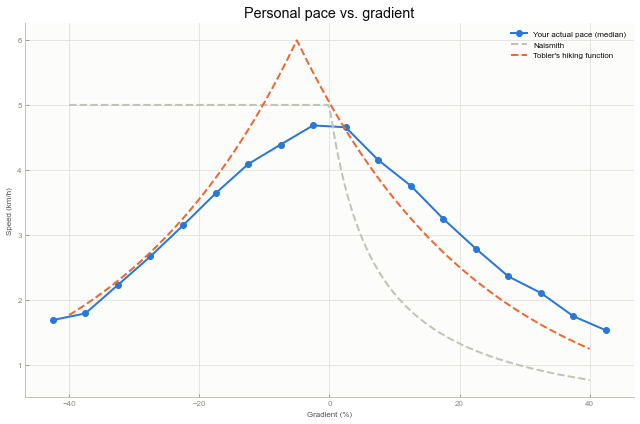

In [16]:
bins = np.arange(-45, 46, 5)
pace_df = pd.DataFrame({"grad": grad, "speed": speed})
pace_df["bin"] = pd.cut(pace_df["grad"], bins)
curve = pace_df.groupby("bin", observed=True)["speed"].median()
mids = np.array([iv.mid for iv in curve.index])

def naismith_speed(g):
    g = np.asarray(g, dtype=float)
    mins = 12 + np.clip(g, 0, None) * 10 / 6
    return 60 / mins

def tobler_speed(g):
    s = np.asarray(g, dtype=float) / 100
    return 6 * np.exp(-3.5 * np.abs(s + 0.05))

g_range = np.linspace(-40, 40, 200)
fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(mids, curve.values, "o-", color=CAT["blue"], label="Your actual pace (median)")
ax.plot(g_range, naismith_speed(g_range), "--", color=MUTED_GRAY, label="Naismith")
ax.plot(g_range, tobler_speed(g_range), "--", color=CAT["orange"], label="Tobler's hiking function")
ax.set_xlabel("Gradient (%)")
ax.set_ylabel("Speed (km/h)")
ax.set_title("Personal pace vs. gradient")
ax.legend()
fig.tight_layout()
plt.show()

In [17]:
flat_mask = np.abs(grad) < 3
flat_pace = np.median(mins_per_km[flat_mask])
flat_kmh = 60 / flat_pace

up_mask = (grad >= 2) & (grad <= 35)
ascent_penalty = np.sum((mins_per_km[up_mask] - flat_pace) * grad[up_mask]) / np.sum(grad[up_mask] ** 2) * 10

down_mask = (grad <= -2) & (grad >= -35)
descent_penalty = -np.sum((mins_per_km[down_mask] - flat_pace) * grad[down_mask]) / np.sum(grad[down_mask] ** 2) * 10

print(f"Flat pace:        {flat_kmh:.2f} km/h  ({flat_pace:.1f} min/km)   [Naismith: 5.0 km/h]")
print(f"Ascent penalty:   {ascent_penalty:.1f} min per 100m climbed      [Naismith: 10.0 min/100m]")
print(f"Descent penalty:  {descent_penalty:.1f} min per 100m descended   [Naismith: 0 - assumed free]")
print()
print("Naismith assumes descending costs nothing. Yours doesn't come close to free - "
      "steep ground, up or down, is expensive on this terrain (scree, boulder, scrambling), "
      "and your peak speed is actually on a gentle downhill, not on the flat.")

Flat pace:        4.73 km/h  (12.7 min/km)   [Naismith: 5.0 km/h]
Ascent penalty:   6.6 min per 100m climbed      [Naismith: 10.0 min/100m]
Descent penalty:  5.3 min per 100m descended   [Naismith: 0 - assumed free]

Naismith assumes descending costs nothing. Yours doesn't come close to free - steep ground, up or down, is expensive on this terrain (scree, boulder, scrambling), and your peak speed is actually on a gentle downhill, not on the flat.


## 12. Fitness trend over time

Using the personal pace model above as a baseline, how does each outing's
*actual* time compare to what the model predicts from its distance and
ascent (approximating descent ≈ ascent, reasonable for loops/there-and-backs)?
The model was fit against raw elapsed time between GPS points (which includes
brief in-motion pauses), while Strava's activity-level `moving_time` strips
stopped time out entirely - the two aren't on the same footing, so the raw
ratio sits systematically below 1.0 rather than centred on it. Normalising by
its own median removes that offset and leaves a genuine relative trend:
below 1.0 = faster than your own personal average pace; above = slower.

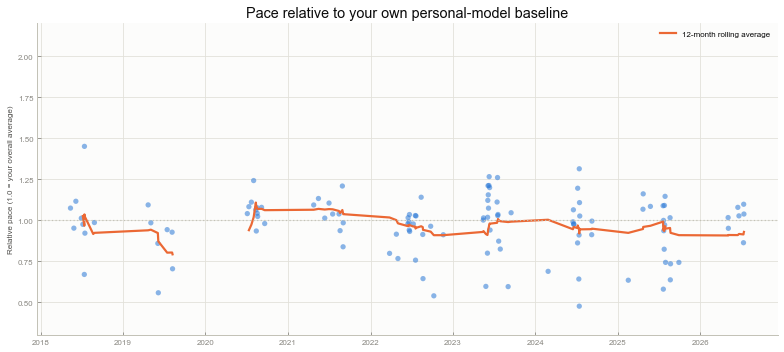

In [18]:
predicted_min = (flat_pace * acts["distance_m"] / 1000
                  + ascent_penalty / 100 * acts["elevation_gain_m"]
                  + descent_penalty / 100 * acts["elevation_gain_m"])
actual_min = acts["moving_time_s"] / 60
raw_ratio = actual_min / predicted_min
acts["effort_ratio"] = raw_ratio / raw_ratio.median()

fig, ax = plt.subplots(figsize=(11, 5))
ax.scatter(acts["date"], acts["effort_ratio"], s=28, color=CAT["blue"], alpha=0.55, edgecolor="none")
roll = acts.set_index("date")["effort_ratio"].rolling("365D", min_periods=5).mean()
ax.plot(roll.index, roll.values, color=CAT["orange"], linewidth=2.2, label="12-month rolling average")
ax.axhline(1.0, color=MUTED_GRAY, linewidth=1.2, linestyle=(0, (1, 2)))
ax.set_ylim(0.3, 2.2)
ax.set_ylabel("Relative pace (1.0 = your overall average)")
ax.set_title("Pace relative to your own personal-model baseline")
ax.legend()
fig.tight_layout()
plt.show()

## 13. Everests climbed

Total ascent across every Munro-bagging day, in multiples of Everest's height (8,849 m).

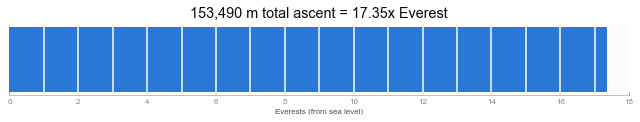

In [19]:
total_ascent = acts["elevation_gain_m"].sum()
everest = 8849
n_everests = total_ascent / everest
n_full = int(n_everests)

fig, ax = plt.subplots(figsize=(9, 1.8))
ax.barh([0], [n_everests], color=CAT["blue"], height=0.5)
for i in range(1, n_full + 1):
    ax.axvline(i, color=SURFACE, linewidth=1.5)
ax.set_xlim(0, n_full + 1)
ax.set_yticks([])
ax.set_xlabel("Everests (from sea level)")
ax.set_title(f"{total_ascent:,.0f} m total ascent = {n_everests:.2f}x Everest")
for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
fig.tight_layout()
plt.show()

## 14. Effort per Munro — hardest days out

`(distance + ascent) per Munro bagged` as a rough proxy for how remote/hard each day was — multi-Munro ridge days dilute this (7 Munros in one long day looks 'easier' per-summit than one huge solo approach), so read it as effort-per-summit-that-day, not a per-hill ranking.

In [20]:
acts["effort_per_munro_km"] = (acts["distance_m"] / 1000 + acts["elevation_gain_m"] / 100) / acts["munro_count"]
hardest = acts.nlargest(10, "effort_per_munro_km")[
    ["date", "name", "munro_count", "distance_m", "elevation_gain_m", "effort_per_munro_km"]
].copy()
hardest["date"] = hardest["date"].dt.date
hardest["distance_km"] = (hardest["distance_m"] / 1000).round(1)
hardest["effort_per_munro_km"] = hardest["effort_per_munro_km"].round(1)
hardest[["date", "name", "munro_count", "distance_km", "elevation_gain_m", "effort_per_munro_km"]].rename(
    columns={"name": "activity", "munro_count": "munros", "elevation_gain_m": "ascent_m"})

,date,activity,munros,distance_km,ascent_m,effort_per_munro_km
54,2022-09-24,Càrn a' Chlamain and Glen Tilt,1,30.4,1109.9,41.5
49,2022-07-19,Baking on Bynack Mor,1,27.1,983.8,37.0
89,2024-07-14,Slioch,1,20.5,1208.0,32.6
111,2026-05-04,Sgùrr a' Mhaoraich,1,18.4,1323.0,31.6
10,2019-04-22,Beinn Bhuidhe,1,22.2,932.2,31.5
84,2024-07-06,Beinn Fhionnlaidh,1,21.1,950.0,30.6
74,2023-07-22,"Treasures, springs and Healers",1,16.0,1265.1,28.6
53,2022-08-21,Beinn Sgritheall,1,13.4,1329.5,26.6
94,2025-04-21,Sgurr nan Gillean,1,15.5,1077.0,26.2
70,2023-07-15,Maol Chean-dearg,1,16.7,898.6,25.6


## 15. Route shape: out-and-back vs. round

How close a track's start and end points are, as a fraction of the total distance covered — near zero means a loop/horseshoe; close to the full distance (well, half of it) means there-and-back.

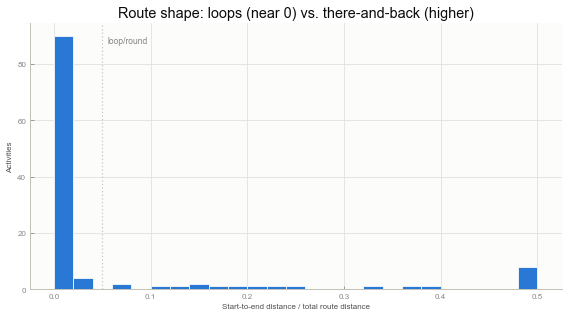

94 / 116 routes with GPS data are tight loops (start ≈ end)


In [21]:
shapes = []
for _, row in acts.iterrows():
    s = load_full_stream(row["id"])
    if not s or "location" not in s or not s["location"]:
        continue
    loc = np.array(s["location"])
    start, end = loc[0], loc[-1]
    mlat = np.radians(loc[:, 0].mean())
    close_km = np.sqrt(((end[0]-start[0])*111)**2 + ((end[1]-start[1])*111*np.cos(mlat))**2)
    dist_km = row["distance_m"] / 1000
    if dist_km > 0:
        shapes.append({"id": row["id"], "name": row["name"], "closure_frac": close_km / dist_km})

shapes_df = pd.DataFrame(shapes)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(shapes_df["closure_frac"].clip(upper=0.5), bins=25, color=CAT["blue"], edgecolor=SURFACE, linewidth=0.8)
ax.axvline(0.05, color=MUTED_GRAY, linestyle=(0, (1, 2)), linewidth=1.2)
ax.text(0.055, ax.get_ylim()[1]*0.95, "loop/round", color=INK_MUTED, fontsize=8.5, va="top")
ax.set_xlabel("Start-to-end distance / total route distance")
ax.set_ylabel("Activities")
ax.set_title("Route shape: loops (near 0) vs. there-and-back (higher)")
fig.tight_layout()
plt.show()

n_loops = (shapes_df["closure_frac"] < 0.05).sum()
print(f"{n_loops} / {len(shapes_df)} routes with GPS data are tight loops (start ≈ end)")

## 16. Bagging streaks and gaps

Longest gap between Munro days: 331 days (2019-08-08 -> 2020-07-04)
Total distinct Munro-bagging days: 116
Median gap between Munro days: 5 days


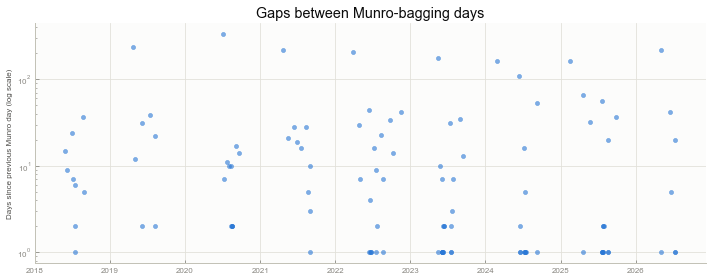

In [22]:
munro_days = acts["date"].dt.normalize().drop_duplicates().sort_values().reset_index(drop=True)
gaps = munro_days.diff().dt.days.dropna()

longest_gap_idx = gaps.idxmax()
longest_gap = gaps.loc[longest_gap_idx]
gap_start = munro_days.loc[longest_gap_idx - 1].date()
gap_end = munro_days.loc[longest_gap_idx].date()

print(f"Longest gap between Munro days: {longest_gap:.0f} days ({gap_start} -> {gap_end})")
print(f"Total distinct Munro-bagging days: {len(munro_days)}")
print(f"Median gap between Munro days: {gaps.median():.0f} days")

fig, ax = plt.subplots(figsize=(10, 4))
ax.scatter(munro_days.iloc[1:], gaps, s=18, color=CAT["blue"], alpha=0.6)
ax.set_yscale("log")
ax.set_ylabel("Days since previous Munro day (log scale)")
ax.set_title("Gaps between Munro-bagging days")
fig.tight_layout()
plt.show()

## 17. Munro Tops: bonus bagging

Every non-Munro summit tagged in the same activities — how many are official Munro Tops (221 of them), bagged along the way?

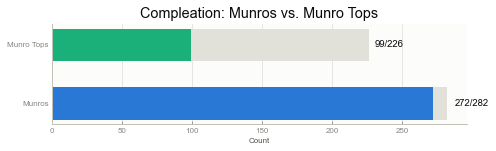

In [23]:
all_summits = []
with open(STRAVA / "munro_activities.jsonl") as f:
    for line in f:
        a = json.loads(line)
        for s in a["summits"]:
            all_summits.append(s)

summits_flat = pd.DataFrame(all_summits)
tops_bagged = summits_flat[summits_flat["classifications"].apply(lambda c: "MT" in c)]["dobih_number"].nunique()
total_tops = sum(1 for h in hills_raw.values() if "MT" in h["Classification"].split(","))

fig, ax = plt.subplots(figsize=(7, 2.2))
for i, (label, bagged, total, color) in enumerate([
    ("Munros", munro_summits["dobih_number"].nunique(), len(all_munros), CAT["blue"]),
    ("Munro Tops", tops_bagged, total_tops, CAT["aqua"]),
]):
    ax.barh([i], [total], color=GRID, height=0.55)
    ax.barh([i], [bagged], color=color, height=0.55)
    ax.text(total + total*0.02, i, f"{bagged}/{total}", va="center", fontsize=9.5, color=INK)
ax.set_yticks([0, 1])
ax.set_yticklabels(["Munros", "Munro Tops"])
ax.set_xlabel("Count")
ax.set_title("Compleation: Munros vs. Munro Tops")
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

## 18. Weekday pattern and how far from Glasgow

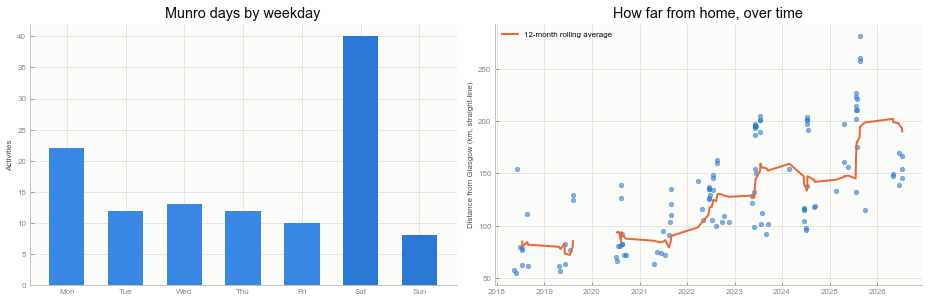

In [24]:
GLASGOW = (55.8642, -4.2518)

start_dists = []
for _, row in acts.iterrows():
    s = load_full_stream(row["id"])
    if not s or "location" not in s or not s["location"]:
        continue
    lat0, lon0 = s["location"][0]
    mlat = np.radians((lat0 + GLASGOW[0]) / 2)
    d_km = np.sqrt(((lat0-GLASGOW[0])*111)**2 + ((lon0-GLASGOW[1])*111*np.cos(mlat))**2)
    start_dists.append({"date": row["date"], "dist_km": d_km})

dist_df = pd.DataFrame(start_dists)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))

ax = axes[0]
weekday_counts = acts["date"].dt.dayofweek.value_counts().reindex(range(7), fill_value=0)
day_labels = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
colors = [CAT["blue"] if i >= 5 else SEQ_BLUE[3] for i in range(7)]
ax.bar(day_labels, weekday_counts.values, color=colors, width=0.6)
ax.set_title("Munro days by weekday")
ax.set_ylabel("Activities")

ax = axes[1]
ax.scatter(dist_df["date"], dist_df["dist_km"], s=22, color=CAT["blue"], alpha=0.6)
roll = dist_df.set_index("date")["dist_km"].sort_index().rolling("365D", min_periods=5).mean()
ax.plot(roll.index, roll.values, color=CAT["orange"], linewidth=2, label="12-month rolling average")
ax.set_ylabel("Distance from Glasgow (km, straight-line)")
ax.set_title("How far from home, over time")
ax.legend()

fig.tight_layout()
plt.show()